In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import string



In [13]:
df = pd.read_csv("/spam_sms.csv")
print(df.head(10))
df.shape

     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
5  spam  FreeMsg Hey there darling it's been 3 week's n...
6   ham  Even my brother is not like to speak with me. ...
7   ham  As per your request 'Melle Melle (Oru Minnamin...
8  spam  WINNER!! As a valued network customer you have...
9  spam  Had your mobile 11 months or more? U R entitle...


(5572, 2)

In [14]:
#data cleaming
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


In [15]:
df.rename(columns={'v1':'target','v2':'text'},inplace=True)
df.sample(5)

,target,text
4539,ham,"Urgh, coach hot, smells of chip fat! Thanks ag..."
3883,spam,A link to your picture has been sent. You can ...
2117,ham,Wish u many many returns of the day.. Happy bi...
4279,spam,WINNER!! As a valued network customer you have...
4556,ham,I am in hospital da. . I will return home in e...


In [16]:
df['target']=df['target'].map({'spam':1,'ham':0})
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [17]:
print('missing value')
print(df.isnull().sum())
print('Duplicate value')
print(df.duplicated().sum())

missing value
target    0
text      0
dtype: int64
Duplicate value
403


In [18]:
#remove duplicate
df=df.drop_duplicates(keep='first')
print(df.duplicated().sum())
print(df.shape)

0
(5169, 2)


In [19]:
#EDA
df['target'].value_counts()

,count
target,
0,4516
1,653


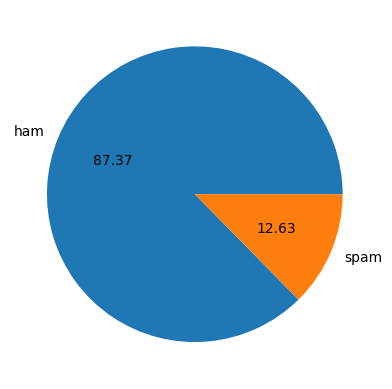

In [20]:
plt.pie(df['target'].value_counts(),labels=['ham','spam'],autopct="%0.2f")
plt.show()

In [21]:
df['num_characters']=df['text'].apply(len)
print(df.head())

   target                                               text  num_characters
0       0  Go until jurong point, crazy.. Available only ...             111
1       0                      Ok lar... Joking wif u oni...              29
2       1  Free entry in 2 a wkly comp to win FA Cup fina...             155
3       0  U dun say so early hor... U c already then say...              49
4       0  Nah I don't think he goes to usf, he lives aro...              61


In [22]:
nltk.download('punkt_tab')
df['num_words'] = df['text'].apply(lambda x: len(nltk.word_tokenize(x)))
df.head()

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


,target,text,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [23]:
df['num_sentences'] = df['text'].apply(lambda x: len(nltk.sent_tokenize(x)))
df.head()

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [24]:
df[['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [25]:
#ham
df[df['target']==0][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [26]:
#spam
df[df['target']==1][['num_characters','num_words','num_sentences']].describe()


,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: xlabel='num_characters', ylabel='Count'>

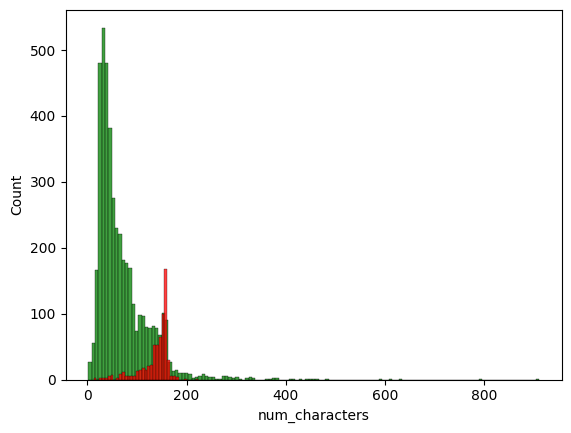

In [27]:
sns.histplot(df[df['target']==0]['num_characters'],color='green')
sns.histplot(df[df['target']==1]['num_characters'],color ='red')

<Axes: xlabel='num_words', ylabel='Count'>

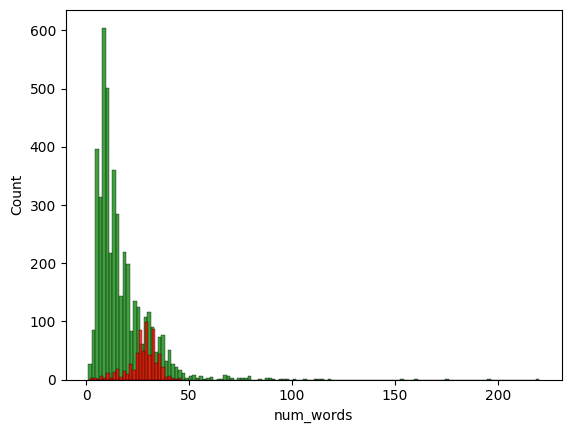

In [28]:
sns.histplot(df[df['target']==0]['num_words'],color='green')
sns.histplot(df[df['target']==1]['num_words'],color ='red')


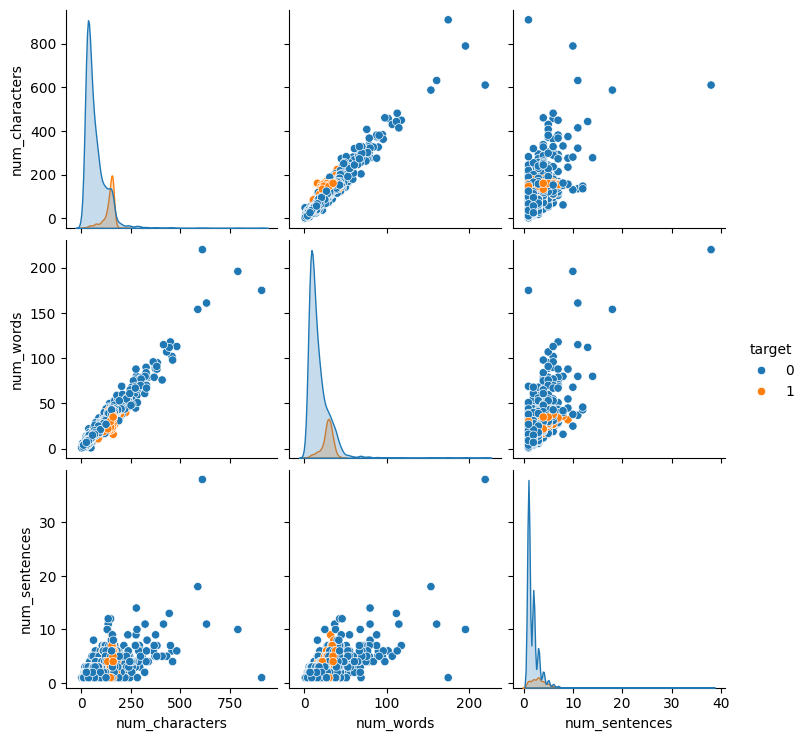

In [29]:
sns.pairplot(df,hue='target')

<Axes: >

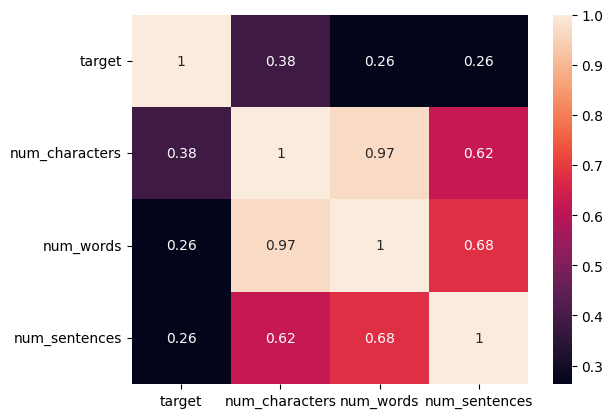

In [30]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [34]:
def transform_text(text):
  text = text.lower()
  text = nltk.word_tokenize(text)
  y =[]
  for i in text:
    if i.isalnum():
      y.append(i)


  text = y[:]
  y.clear()
  for i in text:
    if i not in stopwords.words('english') and i not in string.punctuation:
      y.append(i)

  text = y[:]
  y.clear()
  for i in text:
    y.append(ps.stem(i))

  return " ".join(y)


In [35]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()
df['transform_text'] = df['text'].apply(transform_text)
df.head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,target,text,num_characters,num_words,num_sentences,transform_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


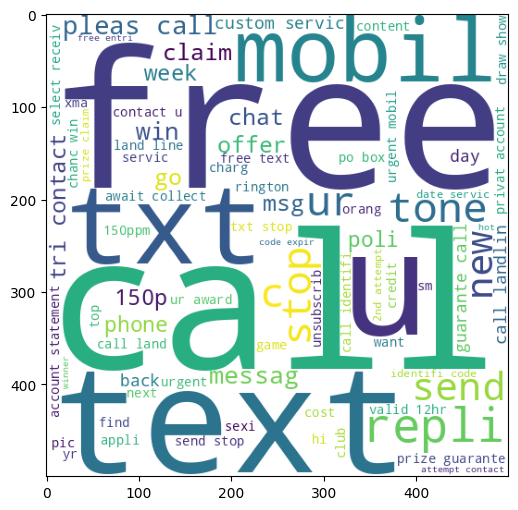

In [36]:
from wordcloud import WordCloud
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white')
spam_wc = wc.generate(df[df['target']==1]['transform_text'].str.cat(sep=" "))
plt.figure(figsize=(15,6))
plt.imshow(spam_wc)


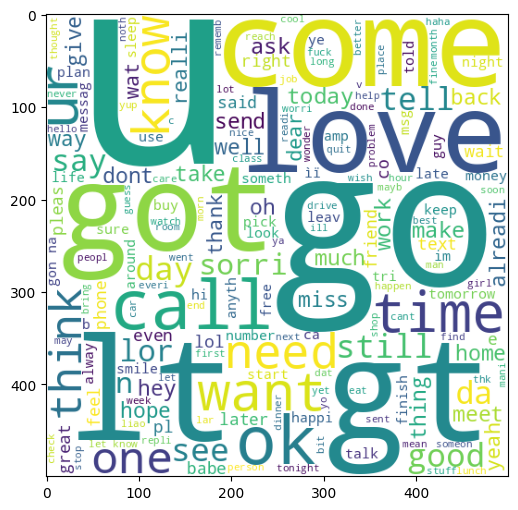

In [37]:
ham_wc = wc.generate(df[df['target']==0]['transform_text'].str.cat(sep=" "))
plt.figure(figsize=(15,6))
plt.imshow(ham_wc)

In [38]:
df.head()

,target,text,num_characters,num_words,num_sentences,transform_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [39]:
spam_corpus=[]
for msg in df[df['target']==1]['transform_text'].tolist():
  for words in msg.split():
    spam_corpus.append(words)

len(spam_corpus)

9939

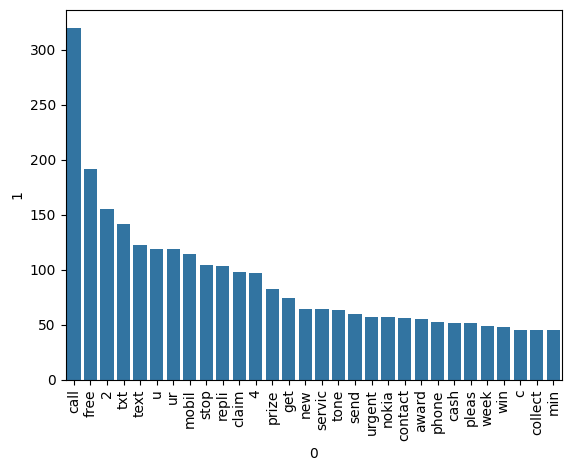

In [40]:
from collections import Counter
df_most_common = pd.DataFrame(Counter(spam_corpus).most_common(30))
sns.barplot(x=df_most_common[0], y=df_most_common[1])
plt.xticks(rotation='vertical')
plt.show()

In [41]:
ham_corpus=[]
for msg in df[df['target']==0]['transform_text'].tolist():
  for words in msg.split():
    ham_corpus.append(words)

len(ham_corpus)

35404

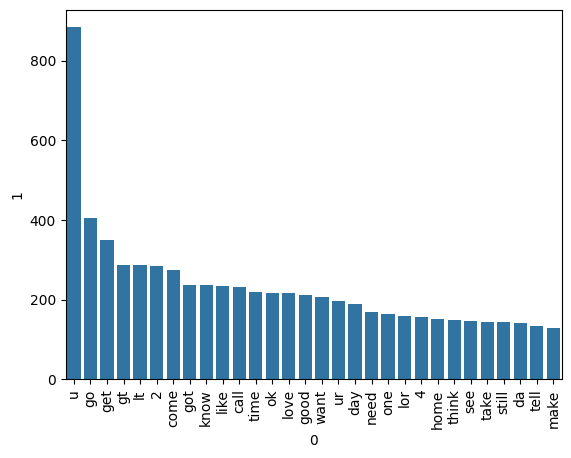

In [42]:
from collections import Counter
df_most_common = pd.DataFrame(Counter(ham_corpus).most_common(30))
sns.barplot(x=df_most_common[0], y=df_most_common[1])
plt.xticks(rotation='vertical')
plt.show()

In [43]:
#model bulding
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)

In [69]:
x = tfidf.fit_transform(df['transform_text']).toarray()
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x = scaler.fit_transform(x)



In [68]:
x = np.hstack((x,df['num_characters'].values.reshape(-1,1)))
x.shape

(5169, 3001)

In [45]:
y = df['target'].values
y

array([0, 0, 1, ..., 0, 0, 0], shape=(5169,))

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [47]:
gnb.fit(x_train, y_train)
y_pred1 = gnb.predict(x_test)
print("accuracy_score",accuracy_score(y_test, y_pred1))
print("confusion_matrix",confusion_matrix(y_test, y_pred1))
print("precision_score", precision_score(y_test, y_pred1))

accuracy_score 0.8762088974854932
confusion_matrix [[784 112]
 [ 16 122]]
precision_score 0.5213675213675214


In [48]:
mnb.fit(x_train, y_train)
y_pred2 = mnb.predict(x_test)
print("accuracy_score",accuracy_score(y_test, y_pred2))
print("confusion_matrix",confusion_matrix(y_test, y_pred2))
print("precision_score", precision_score(y_test, y_pred2))

accuracy_score 0.9787234042553191
confusion_matrix [[889   7]
 [ 15 123]]
precision_score 0.9461538461538461


In [49]:
bnb.fit(x_train, y_train)
y_pred3 = bnb.predict(x_test)
print("accuracy_score",accuracy_score(y_test, y_pred3))
print("confusion_matrix",confusion_matrix(y_test, y_pred3))
print("precision_score", precision_score(y_test, y_pred3))

accuracy_score 0.9835589941972921
confusion_matrix [[895   1]
 [ 16 122]]
precision_score 0.991869918699187


tfidf---mnb

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
svm = SVC(kernel='sigmoid', gamma=1.0)
lr = LogisticRegression(solver='liblinear', penalty='l1')

In [51]:
clf ={
    "svm":svm,
    "lr":lr,
    "mnb":mnb
}

In [52]:
def train_classifier(clf,x_train,y_train,x_test,y_test):
  clf.fit(x_train,y_train)
  y_pred = clf.predict(x_test)
  accuracy = accuracy_score(y_test,y_pred)
  precision = precision_score(y_test,y_pred)

  return accuracy,precision

In [53]:
train_classifier(svm,x_train,y_train,x_test,y_test)

(0.9700193423597679, 0.9421487603305785)

In [54]:
clfs = {
    "svm": svm,
    "lr": lr,
    "mnb": mnb
}

accuracy_scores = []
precision_scores = []

for name, clf_model in clfs.items():
  current_accuracy, current_precision = train_classifier(clf_model, x_train, y_train, x_test, y_test)

  accuracy_scores.append(current_accuracy)
  precision_scores.append(current_precision)

  print('for', name)
  print('accuracy-', current_accuracy)
  print('precision-', current_precision)

performance_df = pd.DataFrame({'Algorithm': clfs.keys(), 'Accuracy': accuracy_scores, 'Precision': precision_scores}).sort_values('Precision', ascending=False)

for svm
accuracy- 0.9700193423597679
precision- 0.9421487603305785
for lr
accuracy- 0.9671179883945842
precision- 0.9642857142857143
for mnb
accuracy- 0.9787234042553191
precision- 0.9461538461538461


In [55]:
performance_df

,Algorithm,Accuracy,Precision
1,lr,0.967118,0.964286
2,mnb,0.978723,0.946154
0,svm,0.970019,0.942149


In [58]:
temp_df = pd.DataFrame({'Algorithm': clfs.keys(), 'Accuracy_max_test_3000': accuracy_scores, 'Precision_max_test_3000': precision_scores}).sort_values('Precision_max_test_3000', ascending=False)

In [63]:
performance_df.merge(temp_df, on='Algorithm')

,Algorithm,Accuracy,Precision,Accuracy_max_test_3000,Precision_max_test_3000
0,lr,0.967118,0.964286,0.967118,0.964286
1,mnb,0.978723,0.946154,0.978723,0.946154
2,svm,0.970019,0.942149,0.970019,0.942149


In [67]:
temp_df = pd.DataFrame({'Algorithm': clfs.keys(), 'Accuracy_scaling': accuracy_scores, 'Precision_scaling': precision_scores}).sort_values('Precision_scaling', ascending=False)
new_df_scaled = new_df.merge(temp_df, on='Algorithm')
new_df_scaled

,Algorithm,Accuracy,Precision,Accuracy_max_test_3000,Precision_max_test_3000,Accuracy_scaling,Precision_scaling
0,lr,0.967118,0.964286,0.967118,0.964286,0.967118,0.964286
1,mnb,0.978723,0.946154,0.978723,0.946154,0.978723,0.946154
2,svm,0.970019,0.942149,0.970019,0.942149,0.970019,0.942149


In [71]:
num_df = pd.DataFrame({'Algorithm': clfs.keys(), 'Accuracy_num_characters': accuracy_scores, 'Precision_num_characters': precision_scores}).sort_values('Precision_num_characters', ascending=False)
new_df_scaled.merge(num_df, on='Algorithm')

,Algorithm,Accuracy,Precision,Accuracy_max_test_3000,Precision_max_test_3000,Accuracy_scaling,Precision_scaling,Accuracy_num_characters,Precision_num_characters
0,lr,0.967118,0.964286,0.967118,0.964286,0.967118,0.964286,0.967118,0.964286
1,mnb,0.978723,0.946154,0.978723,0.946154,0.978723,0.946154,0.978723,0.946154
2,svm,0.970019,0.942149,0.970019,0.942149,0.970019,0.942149,0.970019,0.942149
